In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import scipy as sp
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import axes3d

import threading
from concurrent.futures import ThreadPoolExecutor

ROOT = Path().resolve().parents[1]
sys.path.append(str(ROOT / "src"))

from forward import magcal
from forward import magcal_numba
from forward.thread_func import thread_func

### Differential Inversion
L1-L2 penalty

$$
P(\boldsymbol{\delta \beta}) =  \lambda_1 \left\| \boldsymbol{\delta \beta} \right\|_1 + \frac{\lambda_2}{2} \| \boldsymbol{\delta \beta} \|_2^2
$$

In [2]:
# class for L1-L2 penalty inversion
from inversion.L1L2_penalty_inv import L1L2

In [3]:
# data misfit
def misfit(f, K, beta_star):
    return 0.5 * np.linalg.norm(f - K.dot(beta_star))**2

# penalty
def pen(beta, alpha):
    pen_1 = np.linalg.norm(beta, 1)
    pen_2 = 0.5 * np.linalg.norm(beta, 2)**2
    pen_all = alpha * pen_1 + (1. - alpha) * pen_2
    return pen_all

# curvature
def calcCurvature2(x,y):
    
    dif_x = np.gradient(x)
    dif_y = np.gradient(y)
    dif2_x = np.gradient(dif_x)
    dif2_y = np.gradient(dif_y)
    
    curvature = np.abs(dif2_x * dif_y - dif_x * dif2_y) / (dif_x **2 + dif_y **2)**1.5
    return curvature

### Model domain

In [4]:
### Construction of subsurface grid: xgrd, ygrd, zgrd ###
# incx, incy, incz : grid spacing in x, y, z directions
incx = 0.1
incy = 0.1
incz = 0.1

x = np.arange(-2.4 + 0.5*incx, 2.4, incx)
y = np.arange(-2.4 + 0.5*incy, 2.4, incy)
z = np.arange(-2.4 + 0.5*incz, 0.0, incz)
            
nx = len(x)
ny = len(y)
nz = len(z)
print("nx = {}, ny = {}, nz = {}".format(nx, ny, nz))

### Construction of subsurface grid: xgrd, ygrd, zgrd ###
[yy2, zz2, xx2] = np.meshgrid(y, z, x)
            
xgrd = xx2.reshape(-1)
ygrd = yy2.reshape(-1)
zgrd = zz2.reshape(-1)

# For visualization
xfig, yfig, zfig = [], [], []

for i in range(len(xgrd)):
    j = i // (nx*ny)
    
    # Store coordinates of 8 vertices of each grid cell
    xfig.append([xgrd[i] - 0.5*incx, xgrd[i] + 0.5*incx, xgrd[i] - 0.5*incx, xgrd[i] + 0.5*incx, 
                 xgrd[i] - 0.5*incx, xgrd[i] + 0.5*incx, xgrd[i] - 0.5*incx, xgrd[i] + 0.5*incx])
    yfig.append([ygrd[i] - 0.5*incy, ygrd[i] - 0.5*incy, ygrd[i] + 0.5*incy, ygrd[i] + 0.5*incy, 
                 ygrd[i] - 0.5*incy, ygrd[i] - 0.5*incy, ygrd[i] + 0.5*incy, ygrd[i] + 0.5*incy])
    zfig.append([zgrd[i] - 0.5*incz, zgrd[i] - 0.5*incz, zgrd[i] - 0.5*incz, zgrd[i] - 0.5*incz, 
                 zgrd[i] + 0.5*incz, zgrd[i] + 0.5*incz, zgrd[i] + 0.5*incz, zgrd[i] + 0.5*incz])

# Convert to numpy arrays
xfig = np.array(xfig)
yfig = np.array(yfig)
zfig = np.array(zfig)

# Block size
dim = [[incx / 2., incx / 2.], [incy / 2., incy / 2.], [incz / 2., incz / 2.]]

# Near Tokyo
# Declination (degrees)
dec = -7.
# Inclination (degrees)
inc = 50.

nx = 48, ny = 48, nz = 24


### Aeromagnetic layout (regular grids)

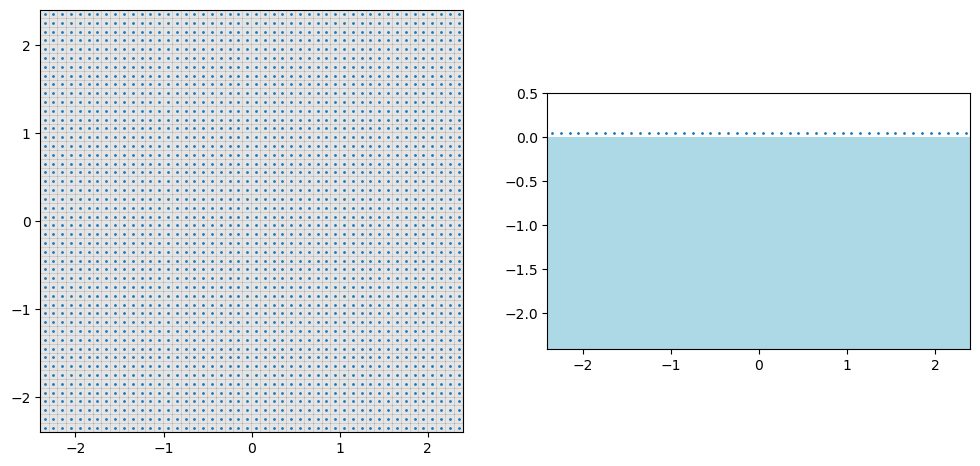

In [5]:
### Generate synthetic data ###
# Coordinate system: x positive east, y positive north, z positive upward

### Observation points: yobs, zobs ###
[xobs1, yobs1] = np.meshgrid(
    np.arange(-2.4 + 0.5*incx, 2.4, incx),
    np.arange(-2.4 + 0.5*incy, 2.4, incy)
)
xobs1 = xobs1.reshape(-1)
yobs1 = yobs1.reshape(-1)
zobs1 = 0.05 *np.ones(len(xobs1))

# Plotting
from matplotlib import cm
from matplotlib.colors import Normalize
import matplotlib.colorbar as clb
from matplotlib import gridspec
from matplotlib.patches import Rectangle

fig = plt.figure(figsize = (12, 6))

ax = fig.add_subplot(121)
ax.pcolor(xx2[0,:,:], yy2[0,:,:], np.zeros(xx2[0,:,:].shape), cmap = "gray", alpha = 0.1)
ax.scatter(xobs1, yobs1, s = 1)
ax.set_aspect("equal")

ax = fig.add_subplot(122)

ax.scatter(xobs1[(0<yobs1)&(yobs1<incy)], zobs1[(0<yobs1)&(yobs1<incy)], s = 1)

# Cross-section visualization
for i in range(len(xgrd)):
    
    # Coordinates
    x, y, z = xfig[i], yfig[i], zfig[i]
    x_min, x_max = min(x), max(x)
    y_min, y_max = min(y), max(y)
    z_min, z_max = min(z), max(z)
    
    # Condition
    if (y_min <= 0.5*incy) & (0.5*incy <= y_max):
        
        # Block dimensions
        width  = x_max - x_min
        height = z_max - z_min

        # Draw rectangle
        rect = Rectangle((x_min, z_min), width, height,
                         facecolor="lightblue", edgecolor='white', linewidth=0.0)
        ax.add_patch(rect)

ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 0.5)
ax.set_aspect("equal")

### Kernel matrix

In [6]:
from numba import njit, prange

@njit(parallel=True, fastmath=True)
def kernel_matrix2(
    exf,
    mgz,
    xobs,
    yobs,
    zobs,
    xgrd,
    ygrd,
    zgrd,
    dim,
    L
):

    nobs  = xobs.shape[0]
    ncell = xgrd.shape[0]

    xmin = np.min(xgrd)
    xmax = np.max(xgrd)

    ymin = np.min(ygrd)
    ymax = np.max(ygrd)

    K = np.zeros((nobs, ncell))

    for s in prange(ncell):

        dx1 = dim[0,0]
        dx2 = dim[0,1]

        dy1 = dim[1,0]
        dy2 = dim[1,1]

        dz1 = dim[2,0]
        dz2 = dim[2,1]

        if abs(xgrd[s] - xmin) < 1e-10:
            dx1 += L
        elif abs(xgrd[s] - xmax) < 1e-10:
            dx2 += L

        if abs(ygrd[s] - ymin) < 1e-10:
            dy1 += L
        elif abs(ygrd[s] - ymax) < 1e-10:
            dy2 += L

        dim_new = np.empty((3,2))

        dim_new[0,0] = dx1
        dim_new[0,1] = dx2

        dim_new[1,0] = dy1
        dim_new[1,1] = dy2

        dim_new[2,0] = dz1
        dim_new[2,1] = dz2

        h = magcal_numba.prism(
            mgz,
            xobs,
            yobs,
            zobs,
            xgrd[s],
            ygrd[s],
            zgrd[s],
            dim_new
        )

        K[:,s] = magcal_numba.total_force(exf, h)

        if s%1000 == 0: 
            print(s) 

    return K

In [7]:
%%time
# num of threads
from numba import set_num_threads, get_num_threads
set_num_threads(12)
print(get_num_threads())

# Unit vector creation
mgz = magcal.di2xyz(dec = dec, inc = inc)
exf = mgz.copy()

# Kernel matrix
K1 = kernel_matrix2(
     exf,
     mgz,
     xobs1.astype(np.float64),
     yobs1.astype(np.float64),
     zobs1.astype(np.float64),
     xgrd.astype(np.float64),
     ygrd.astype(np.float64),
     zgrd.astype(np.float64),
     np.array(dim, dtype=np.float64),
     1000.0
)

12
0
37000
14000
51000
28000
5000
42000
19000
33000
10000
47000
24000
1000
38000
15000
52000
29000
6000
43000
20000
34000
11000
48000
25000
2000
39000
16000
53000
30000
7000
44000
21000
35000
12000
49000
26000
3000
40000
17000
54000
31000
8000
45000
22000
36000
13000
50000
27000
4000
41000
18000
55000
32000
9000
46000
23000
CPU times: total: 3min 14s
Wall time: 48.5 s


In [8]:
# Depth weighting
w1 = np.linalg.norm(K1, axis=0)
X1 = K1 / w1

### Input models

In [9]:
### Magnetization structure  ###

# ------------------------------------------------------------ #

# Time 1
beta1 = 0 * np.ones(len(xgrd))
for iz in range(nz):
    for iy in range(ny):
        for ix in range(nx):
            k = ix + iy*nx + iz*nx*ny

            # 東: migration
            if (0.2 < xgrd[k]) & (xgrd[k] < 0.8) & (-0.3 < ygrd[k]) & (ygrd[k] < 0.3) & (-1.0 < zgrd[k]) & (zgrd[k] < -0.4):
                beta1[k] = -4

            # 西: diffusion
            if (-1.4 < xgrd[k]) & (xgrd[k] < -0.6) & (-0.4 < ygrd[k]) & (ygrd[k] < 0.4) & (-1.7 < zgrd[k]) & (zgrd[k] < -0.9):
                beta1[k] = -3

# Time 2
beta2 = 0 * np.ones(len(xgrd))
for iz in range(nz):
    for iy in range(ny):
        for ix in range(nx):
            k = ix + iy*nx + iz*nx*ny

            # 東: migration
            if (0.4 < xgrd[k]) & (xgrd[k] < 1.0) & (-0.3 < ygrd[k]) & (ygrd[k] < 0.3) & (-1.0 < zgrd[k]) & (zgrd[k] < -0.4):
                beta2[k] = -4

            # 西: diffusion
            if (-1.4 < xgrd[k]) & (xgrd[k] < -0.6) & (-0.4 < ygrd[k]) & (ygrd[k] < 0.4) & (-1.7 < zgrd[k]) & (zgrd[k] < -0.7):
                beta2[k] = -3


# Time 3
beta3 = 0 * np.ones(len(xgrd))
for iz in range(nz):
    for iy in range(ny):
        for ix in range(nx):
            k = ix + iy*nx + iz*nx*ny

            # 東: migration
            if (0.6 < xgrd[k]) & (xgrd[k] < 1.2) & (-0.3 < ygrd[k]) & (ygrd[k] < 0.3) & (-1.0 < zgrd[k]) & (zgrd[k] < -0.4):
                beta3[k] = -4

            # 西: diffusion
            if (-1.4 < xgrd[k]) & (xgrd[k] < -0.6) & (-0.4 < ygrd[k]) & (ygrd[k] < 0.4) & (-1.7 < zgrd[k]) & (zgrd[k] < -0.5):
                beta3[k] = -3
                
# Time 4
beta4 = 0 * np.ones(len(xgrd))
for iz in range(nz):
    for iy in range(ny):
        for ix in range(nx):
            k = ix + iy*nx + iz*nx*ny

            # 東: migration
            if (0.8 < xgrd[k]) & (xgrd[k] < 1.4) & (-0.3 < ygrd[k]) & (ygrd[k] < 0.3) & (-1.0 < zgrd[k]) & (zgrd[k] < -0.4):
                beta4[k] = -4

            # 西: diffusion
            if (-1.4 < xgrd[k]) & (xgrd[k] < -0.6) & (-0.4 < ygrd[k]) & (ygrd[k] < 0.4) & (-1.7 < zgrd[k]) & (zgrd[k] < -0.3):
                beta4[k] = -3
                
bb1 = beta1.reshape(nz, ny, nx)
bb2 = beta2.reshape(nz, ny, nx)
bb3 = beta3.reshape(nz, ny, nx)
bb4 = beta4.reshape(nz, ny, nx)

# ------------------------------------------------------------ #

# Magnetic anomaly calculation
f1_row = K1.dot(beta1)
f2_row = K1.dot(beta2)
f3_row = K1.dot(beta3)
f4_row = K1.dot(beta4)

# Add Gaussian noise
np.random.seed(42)
noise1 = np.random.normal(loc=0, scale=5.0, size=len(f1_row))  # 5 nT
noise2 = np.random.normal(loc=0, scale=5.0, size=len(f2_row))  # 5 nT
noise3 = np.random.normal(loc=0, scale=5.0, size=len(f3_row))  # 5 nT
noise4 = np.random.normal(loc=0, scale=5.0, size=len(f4_row))  # 5 nT

fobs1 = f1_row + noise1
fobs2 = f2_row + noise2
fobs3 = f3_row + noise3
fobs4 = f4_row + noise4

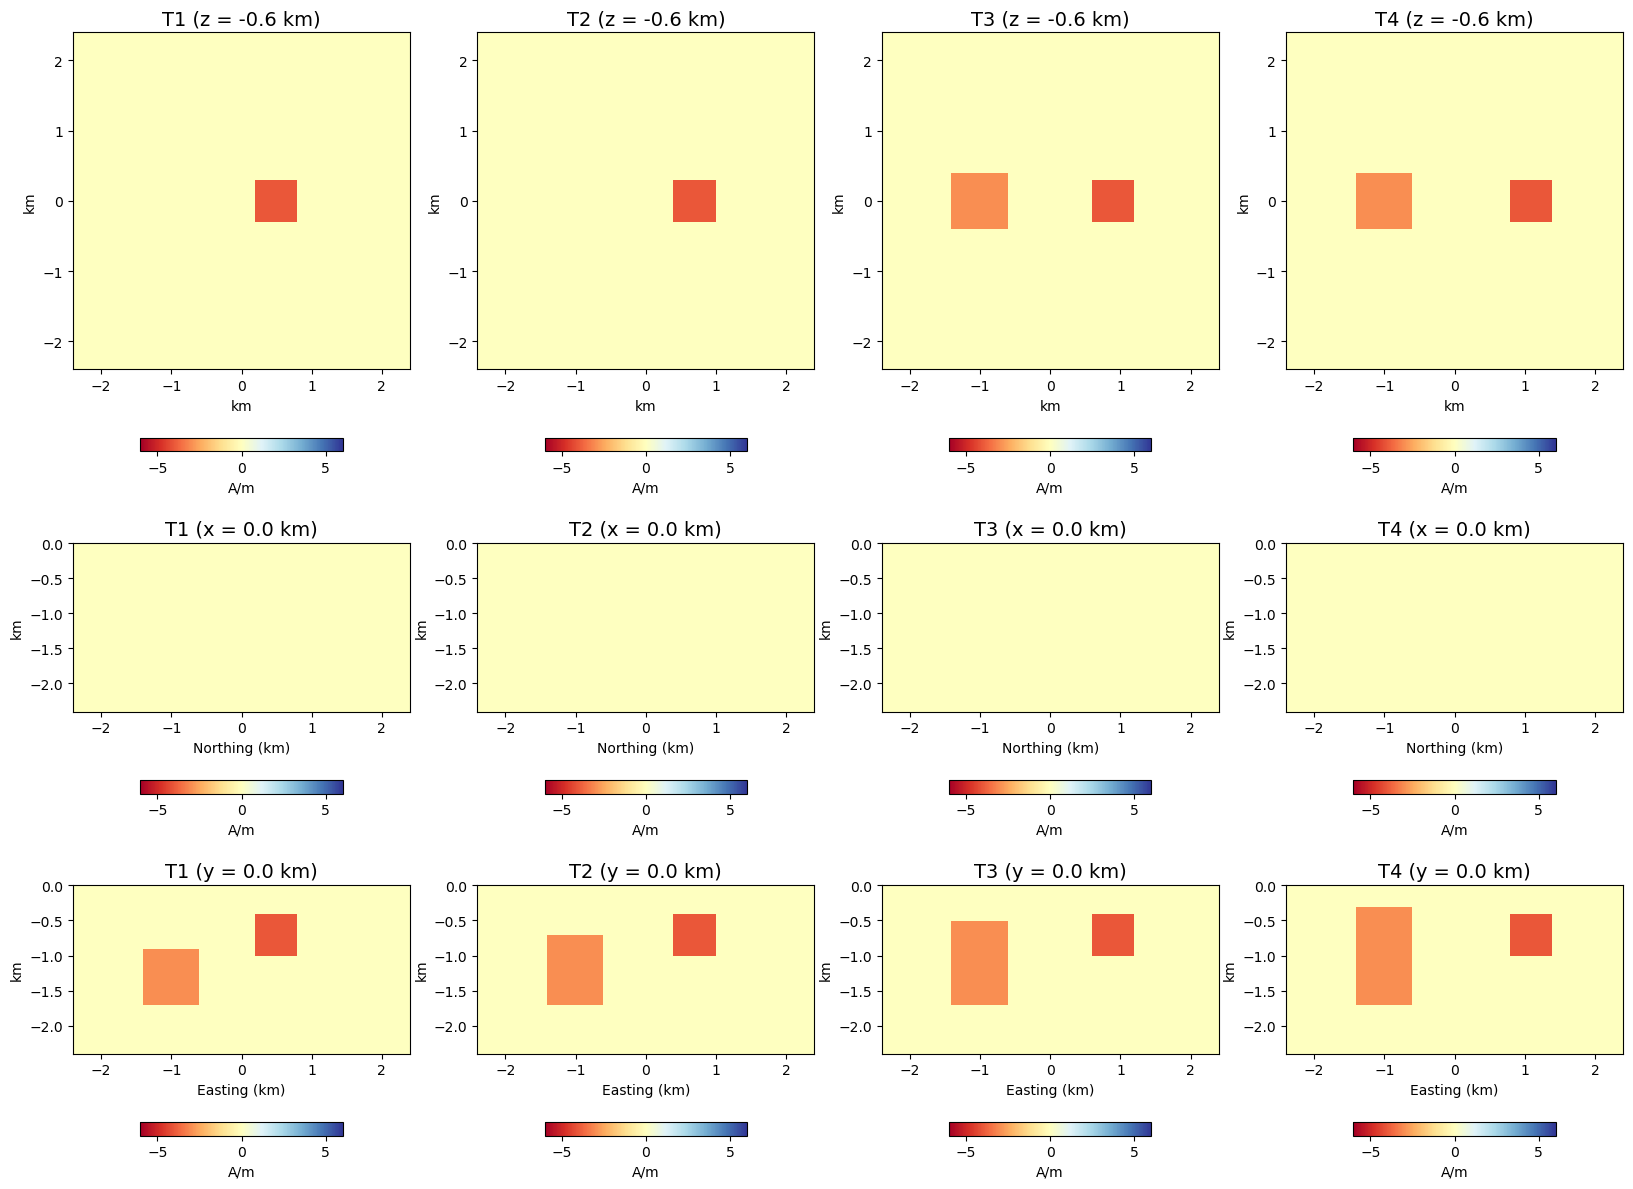

In [10]:
fig = plt.figure(figsize = (20, 20))

x_slice =  0.0
y_slice =  0.0
z_slice = -0.6

ax = fig.add_subplot(341)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              bb1[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T1 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(342)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              bb2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(343)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              bb3[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(344)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              bb4[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(345)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              bb1[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T1 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(346)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              bb2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(347)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              bb3[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(348)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              bb4[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(349)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              bb1[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T1 (y = {:.1f} km)".format(y_slice), fontsize = 14)

ax = fig.add_subplot(3,4,10)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              bb2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 (y = {:.1f} km)".format(y_slice), fontsize = 14)

ax = fig.add_subplot(3,4,11)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              bb3[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 (y = {:.1f} km)".format(y_slice), fontsize = 14)


ax = fig.add_subplot(3,4,12)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              bb4[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "RdYlBu"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)
ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 (y = {:.1f} km)".format(y_slice), fontsize = 14)

plt.subplots_adjust(hspace=-0.6)

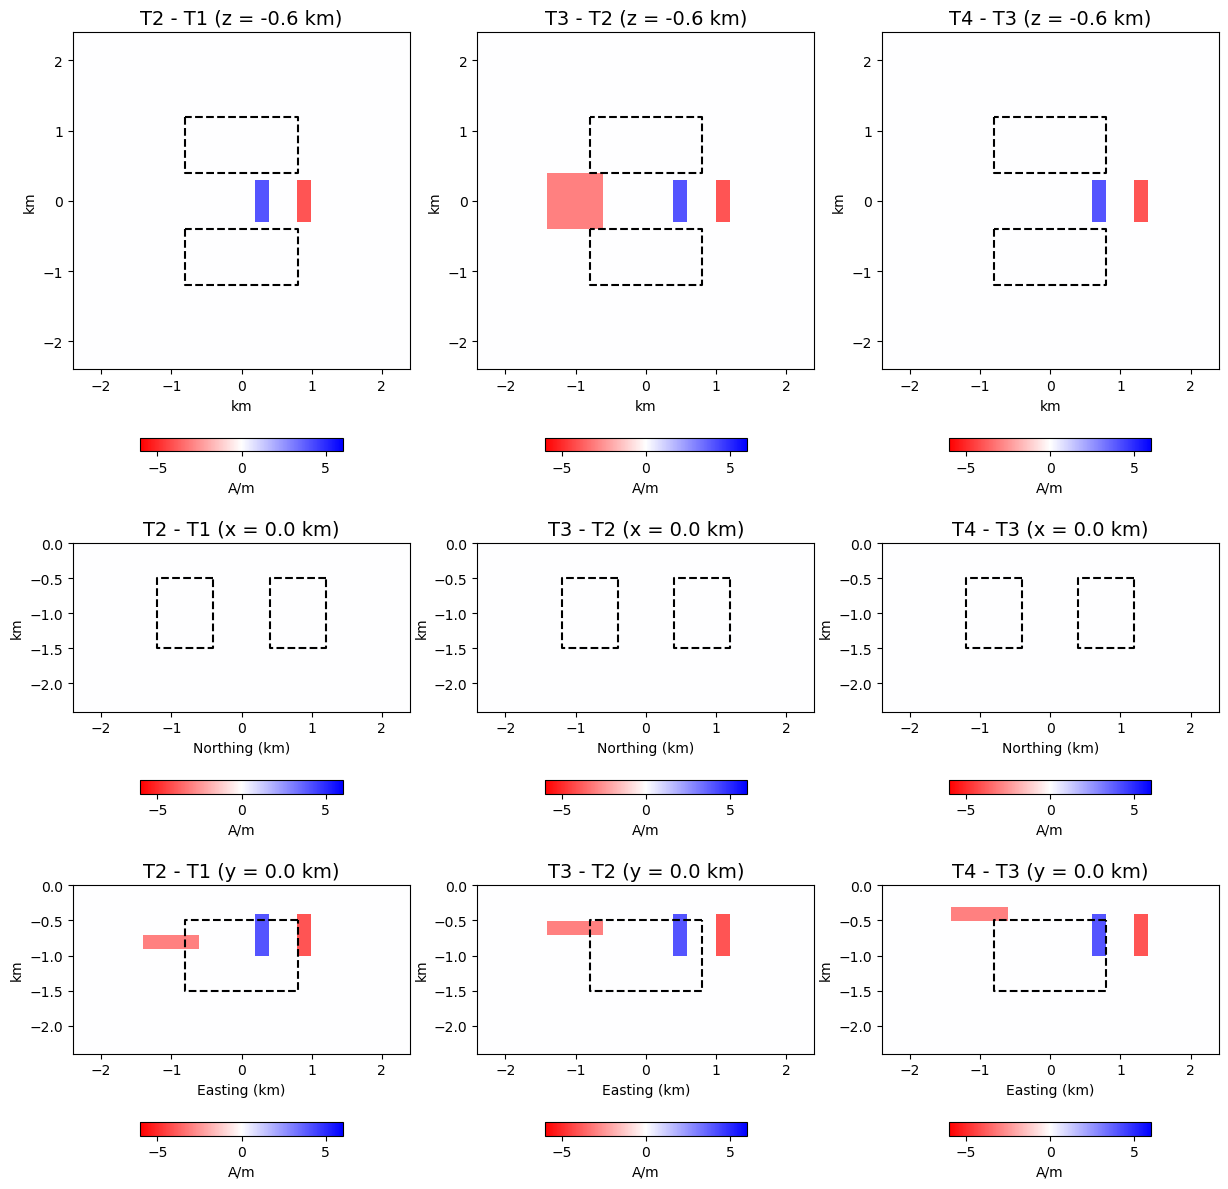

In [11]:
fig = plt.figure(figsize = (20, 20))

x_slice =  0.0
y_slice =  0.0
z_slice = -0.6

ax = fig.add_subplot(341)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              (bb2 - bb1)[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([-0.8, -0.8, 0.8, 0.8, -0.8], [1.2, 0.4, 0.4, 1.2, 1.2], "--", color = "k")
ax.plot([-0.8, -0.8, 0.8, 0.8, -0.8], [-0.4, -1.2, -1.2, -0.4, -0.4], "--", color = "k")

ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 - T1 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(342)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              (bb3 - bb2)[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([-0.8, -0.8, 0.8, 0.8, -0.8], [1.2, 0.4, 0.4, 1.2, 1.2], "--", color = "k")
ax.plot([-0.8, -0.8, 0.8, 0.8, -0.8], [-0.4, -1.2, -1.2, -0.4, -0.4], "--", color = "k")

ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 - T2 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(343)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              (bb4 - bb3)[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([-0.8, -0.8, 0.8, 0.8, -0.8], [1.2, 0.4, 0.4, 1.2, 1.2], "--", color = "k")
ax.plot([-0.8, -0.8, 0.8, 0.8, -0.8], [-0.4, -1.2, -1.2, -0.4, -0.4], "--", color = "k")

ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 - T3 (z = {:.1f} km)".format(z_slice), fontsize = 14)


ax = fig.add_subplot(345)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              (bb2 - bb1)[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([1.2, 0.4, 0.4, 1.2, 1.2], [-0.5, -0.5, -1.5, -1.5, -0.5], "--", color = "k")
ax.plot([-0.4, -1.2, -1.2, -0.4, -0.4], [-0.5, -0.5, -1.5, -1.5, -0.5], "--", color = "k")

ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 - T1 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(346)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              (bb3 - bb2)[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([1.2, 0.4, 0.4, 1.2, 1.2], [-0.5, -0.5, -1.5, -1.5, -0.5], "--", color = "k")
ax.plot([-0.4, -1.2, -1.2, -0.4, -0.4], [-0.5, -0.5, -1.5, -1.5, -0.5], "--", color = "k")

ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 - T2 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(347)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              (bb4 - bb3)[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([1.2, 0.4, 0.4, 1.2, 1.2], [-0.5, -0.5, -1.5, -1.5, -0.5], "--", color = "k")
ax.plot([-0.4, -1.2, -1.2, -0.4, -0.4], [-0.5, -0.5, -1.5, -1.5, -0.5], "--", color = "k")

ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 - T3 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(349)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              (bb2 - bb1)[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([0.8, -0.8, -0.8, 0.8, 0.8], [-0.5, -0.5, -1.5, -1.5, -0.5], "--", color = "k")

ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 - T1 (y = {:.1f} km)".format(y_slice), fontsize = 14)

ax = fig.add_subplot(3,4,10)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              (bb3 - bb2)[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([0.8, -0.8, -0.8, 0.8, 0.8], [-0.5, -0.5, -1.5, -1.5, -0.5], "--", color = "k")

ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 - T2 (y = {:.1f} km)".format(y_slice), fontsize = 14)

ax = fig.add_subplot(3,4,11)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              (bb4 - bb3)[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([0.8, -0.8, -0.8, 0.8, 0.8], [-0.5, -0.5, -1.5, -1.5, -0.5], "--", color = "k")

ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 - T3 (y = {:.1f} km)".format(y_slice), fontsize = 14)

plt.subplots_adjust(hspace=-0.6)

C:\Users\ri710\AppData\Local\Temp\ipykernel_51528\1558572479.py:24: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap("turbo")
C:\Users\ri710\AppData\Local\Temp\ipykernel_51528\1558572479.py:52: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap("turbo")
C:\Users\ri710\AppData\Local\Temp\ipykernel_51528\1558572479.py:80: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap("turbo")
C:\Users\ri710\AppData\Local\Temp\ipykernel_51528\15585

Text(0.5, 1.0, 'Magnetic anomaly (nT)')

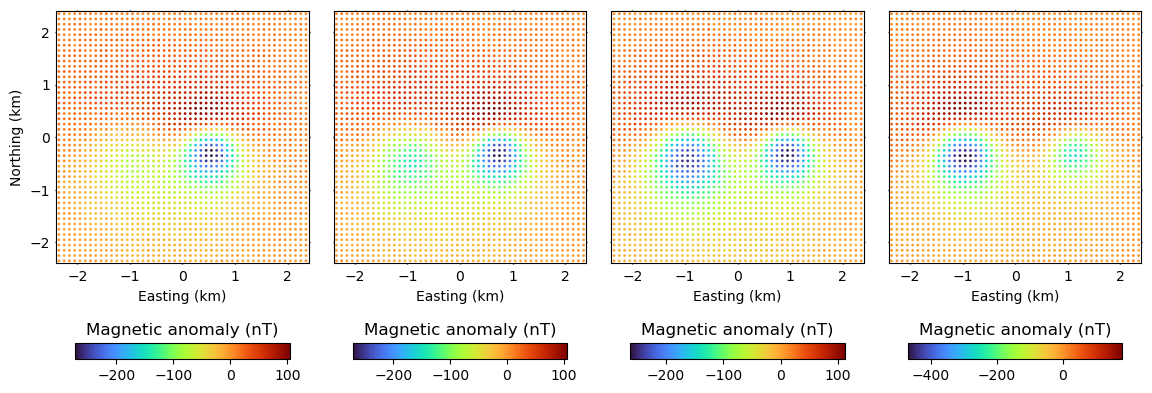

In [12]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib as mpl

# Plot
fig = plt.figure(figsize = (14, 12.5))
plt.subplots_adjust(wspace=0.1, hspace=-0.3)

### data ###

# T = T_1
ax = fig.add_subplot(5,4,17)
p = ax.scatter(xobs1, yobs1, c = fobs1, cmap = "turbo", s = 1)
#p.set_clim(-200, 100)
ax.set_aspect("equal")
ax.set_xlabel("Easting (km)")
ax.set_ylabel("Northing (km)")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 2.4)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(width = 1, length = 1)

#--- colorbar ---# 
cmap = cm.get_cmap("turbo")
norm = Normalize(vmin = fobs1.min(), vmax = fobs1.max())
p = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
p.set_array([])
cax = inset_axes(ax,
                 width="85%", 
                 height="10%",
                 loc='lower center',
                 bbox_to_anchor=(0, -0.38, 1, 0.65), 
                 bbox_transform=ax.transAxes,
                 borderpad=0)
cbar = fig.colorbar(p, cax=cax, orientation="horizontal")
cbar.ax.set_title("Magnetic anomaly (nT)", fontsize = 12)

# T = T_2
ax = fig.add_subplot(5,4,18)
p = ax.scatter(xobs1, yobs1, c = fobs2, cmap = "turbo", s = 1)
#p.set_clim(-100, 50)
ax.set_aspect("equal")
ax.set_xlabel("Easting (km)")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 2.4)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False, )
ax.tick_params(width = 1, length = 1)

#--- colorbar ---#
cmap = cm.get_cmap("turbo")
norm = Normalize(vmin = fobs2.min(), vmax = fobs2.max())
p = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
p.set_array([]) 
cax = inset_axes(ax,
                 width="85%", 
                 height="10%", 
                 loc='lower center',
                 bbox_to_anchor=(0, -0.38, 1, 0.65),
                 bbox_transform=ax.transAxes,
                 borderpad=0)
cbar = fig.colorbar(p, cax=cax, orientation="horizontal")
cbar.ax.set_title("Magnetic anomaly (nT)", fontsize = 12)

# T = T_3
ax = fig.add_subplot(5,4,19)
p = ax.scatter(xobs1, yobs1, c = fobs3, cmap = "turbo", s = 1)
#p.set_clim(-30, 50)
ax.set_aspect("equal")
ax.set_xlabel("Easting (km)")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 2.4)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False, )
ax.tick_params(width = 1, length = 1)

#--- colorbar ---#
cmap = cm.get_cmap("turbo")
norm = Normalize(vmin = fobs3.min(), vmax = fobs3.max())
p = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
p.set_array([]) 
cax = inset_axes(ax,
                 width="85%",
                 height="10%",
                 loc='lower center',
                 bbox_to_anchor=(0, -0.38, 1, 0.65), 
                 bbox_transform=ax.transAxes,
                 borderpad=0)
cbar = fig.colorbar(p, cax=cax, orientation="horizontal")
cbar.ax.set_title("Magnetic anomaly (nT)", fontsize = 12)

# T = T_4
ax = fig.add_subplot(5,4,20)
p = ax.scatter(xobs1, yobs1, c = fobs4, cmap = "turbo", s = 1)
#p.set_clim(-100, 200)
ax.set_aspect("equal")
ax.set_xlabel("Easting (km)")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 2.4)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False, )
ax.tick_params(width = 1, length = 1)

#--- colorbar ---#
cmap = cm.get_cmap("turbo")
norm = Normalize(vmin = fobs4.min(), vmax = fobs4.max())
p = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
p.set_array([]) 
cax = inset_axes(ax,
                 width="85%", 
                 height="10%", 
                 loc='lower center',
                 bbox_to_anchor=(0, -0.38, 1, 0.65),
                 bbox_transform=ax.transAxes,
                 borderpad=0)
cbar = fig.colorbar(p, cax=cax, orientation="horizontal")
cbar.ax.set_title("Magnetic anomaly (nT)", fontsize = 12)

C:\Users\ri710\AppData\Local\Temp\ipykernel_51528\3404334352.py:29: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap("bwr")
C:\Users\ri710\AppData\Local\Temp\ipykernel_51528\3404334352.py:57: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap("bwr")
C:\Users\ri710\AppData\Local\Temp\ipykernel_51528\3404334352.py:85: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = cm.get_cmap("bwr")


Text(0.5, 1.0, 'Magnetic anomaly (nT)')

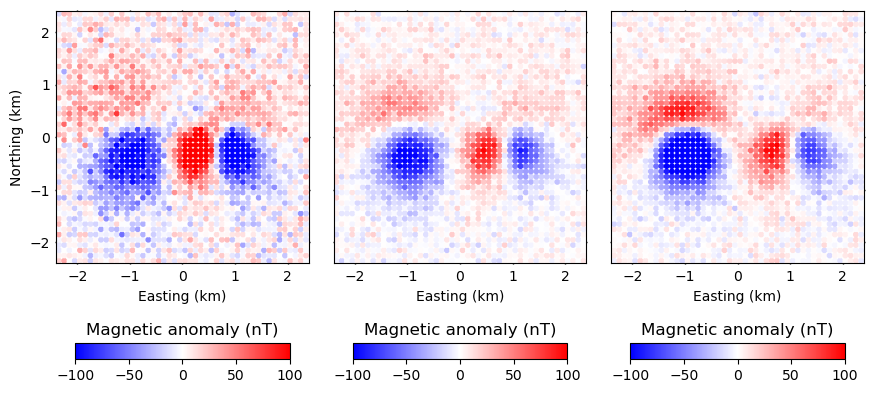

In [13]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib as mpl

# Plot
fig = plt.figure(figsize = (14, 12.5))
plt.subplots_adjust(wspace=0.1, hspace=-0.3)

### data ###

# Centering
fobs_del12 = (fobs2 - fobs1) - (fobs2 - fobs1).mean()
fobs_del23 = (fobs3 - fobs2) - (fobs3 - fobs2).mean()
fobs_del34 = (fobs4 - fobs3) - (fobs4 - fobs3).mean()

# T_2 - T_1
ax = fig.add_subplot(5,4,17)
p = ax.scatter(xobs1, yobs1, c = fobs_del12, cmap = "bwr", s = 10)
p.set_clim(-50, 50)
ax.set_aspect("equal")
ax.set_xlabel("Easting (km)")
ax.set_ylabel("Northing (km)")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 2.4)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(width = 1, length = 1)

#--- colorbar ---# 
cmap = cm.get_cmap("bwr")
norm = Normalize(vmin = -100, vmax = 100)
p = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
p.set_array([])
cax = inset_axes(ax,
                 width="85%", 
                 height="10%",
                 loc='lower center',
                 bbox_to_anchor=(0, -0.38, 1, 0.65), 
                 bbox_transform=ax.transAxes,
                 borderpad=0)
cbar = fig.colorbar(p, cax=cax, orientation="horizontal")
cbar.ax.set_title("Magnetic anomaly (nT)", fontsize = 12)

# T_3 - T_2
ax = fig.add_subplot(5,4,18)
p = ax.scatter(xobs1, yobs1, c = fobs_del23, cmap = "bwr", s = 10)
p.set_clim(-100, 100)
ax.set_aspect("equal")
ax.set_xlabel("Easting (km)")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 2.4)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False, )
ax.tick_params(width = 1, length = 1)

#--- colorbar ---#
cmap = cm.get_cmap("bwr")
norm = Normalize(vmin = -100, vmax = 100)
p = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
p.set_array([]) 
cax = inset_axes(ax,
                 width="85%", 
                 height="10%", 
                 loc='lower center',
                 bbox_to_anchor=(0, -0.38, 1, 0.65),
                 bbox_transform=ax.transAxes,
                 borderpad=0)
cbar = fig.colorbar(p, cax=cax, orientation="horizontal")
cbar.ax.set_title("Magnetic anomaly (nT)", fontsize = 12)

# T_4 - T_3
ax = fig.add_subplot(5,4,19)
p = ax.scatter(xobs1, yobs1, c = fobs_del34, cmap = "bwr", s = 10)
p.set_clim(-100, 100)
ax.set_aspect("equal")
ax.set_xlabel("Easting (km)")
ax.set_xlim(-2.4, 2.4)
ax.set_ylim(-2.4, 2.4)
ax.xaxis.set_ticks_position('both')
ax.yaxis.set_ticks_position('both')
ax.tick_params(labelleft=False, )
ax.tick_params(width = 1, length = 1)

#--- colorbar ---#
cmap = cm.get_cmap("bwr")
norm = Normalize(vmin = -100, vmax = 100)
p = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
p.set_array([]) 
cax = inset_axes(ax,
                 width="85%",
                 height="10%",
                 loc='lower center',
                 bbox_to_anchor=(0, -0.38, 1, 0.65), 
                 bbox_transform=ax.transAxes,
                 borderpad=0)
cbar = fig.colorbar(p, cax=cax, orientation="horizontal")
cbar.ax.set_title("Magnetic anomaly (nT)", fontsize = 12)


### Differential Inversion

In [15]:
# hyper-parameters
lams = np.power(10., np.arange(0., 2.6, 0.25))
print("lams = {}".format(lams))

# ratio of L1 norm and L2 norm
alpha_ = 0.9

lams = [  1.           1.77827941   3.16227766   5.62341325  10.
  17.7827941   31.6227766   56.23413252 100.         177.827941
 316.22776602]


In [ ]:
%%time
params_all = []
betas_del12_all = []
betas_del23_all = []
betas_del34_all = []

for li in range(len(lams)):

    params_all.append(lams[li])
    
    l_1 = lams[li] * alpha_
    l_2 = lams[li] * (1. - alpha_)
    print("λ1 = {}, λ2 = {}".format(l_1, l_2))
    
    # インバージョン解析を実行
    model1 = L1L2(l_1, l_2, rho_=1.0, eta_=0.0, fit_intercept = False, eps_ADMM = 1.e-3)
    model1.algorithm(X1, fobs_del12, w1)
    beta_sim_del12 = model1.beta_ / w1
    
    model2 = L1L2(l_1, l_2, rho_=1.0, eta_=0.0, fit_intercept = False, eps_ADMM = 1.e-3)
    model2.algorithm(X1, fobs_del23, w1)
    beta_sim_del23 = model2.beta_ / w1
    
    model3 = L1L2(l_1, l_2, rho_=1.0, eta_=0.0, fit_intercept = False, eps_ADMM = 1.e-3)
    model3.algorithm(X1, fobs_del34, w1)
    beta_sim_del34 = model3.beta_ / w1

    betas_del12_all.append(beta_sim_del12)
    betas_del23_all.append(beta_sim_del23)
    betas_del34_all.append(beta_sim_del34)

# ndarry
params_all = np.array(params_all)
betas_del12_all = np.array(betas_del12_all)
betas_del23_all = np.array(betas_del23_all)
betas_del34_all = np.array(betas_del34_all)

λ1 = 0.9, λ2 = 0.09999999999999998
intercept = False
no-constrained
iter = 0, delta = 0.41163872760003856
Converged at iteration 105
intercept = False
no-constrained
iter = 0, delta = 0.4126657534994532
Converged at iteration 108
intercept = False
no-constrained
iter = 0, delta = 0.4781505533223361
Converged at iteration 113
λ1 = 1.6004514690350304, λ2 = 0.17782794100389224
intercept = False
no-constrained
iter = 0, delta = 0.43375295040473094
Converged at iteration 174
intercept = False
no-constrained
iter = 0, delta = 0.4545731916412817
Converged at iteration 186
intercept = False
no-constrained
iter = 0, delta = 0.5094889632354566
Converged at iteration 193
λ1 = 2.8460498941515415, λ2 = 0.3162277660168379
intercept = False
no-constrained
iter = 0, delta = 0.559053468703684
Converged at iteration 318
intercept = False
no-constrained
iter = 0, delta = 0.5774241340061315
Converged at iteration 339
intercept = False
no-constrained
iter = 0, delta = 0.6516104746529271
Converged at iterat

In [ ]:
import pickle
with open('1007_Params_model_B_differential.pickle', 'wb') as f:
    pickle.dump(params_all, f)
with open('1007_betas_del12_model_B_differential.pickle', 'wb') as f:
    pickle.dump(betas_del12_all, f)
with open('1007_betas_del23_model_B_differential.pickle', 'wb') as f:
    pickle.dump(betas_del23_all, f)
with open('1007_betas_del34_model_B_differential.pickle', 'wb') as f:
    pickle.dump(betas_del34_all, f)

In [23]:
# calc rss, pen
# T2 - T1
rss_temp_del12 = []
pen_temp_del12 = []
for i in range(len(lams)):
    rss_temp_del12.append(misfit(fobs2 - fobs1, K1, betas_del12_all[i]))
    pen_temp_del12.append(pen(betas_del12_all[i]*w1, alpha=0.9))
    
# T3 - T2
rss_temp_del23 = []
pen_temp_del23 = []
for i in range(len(lams)):
    rss_temp_del23.append(misfit(fobs3 - fobs2, K1, betas_del23_all[i]))
    pen_temp_del23.append(pen(betas_del23_all[i]*w1, alpha=0.9))

# T4 - T3
rss_temp_del34 = []
pen_temp_del34 = []
for i in range(len(lams)):
    rss_temp_del34.append(misfit(fobs4 - fobs3, K1, betas_del34_all[i]))
    pen_temp_del34.append(pen(betas_del34_all[i]*w1, alpha=0.9))

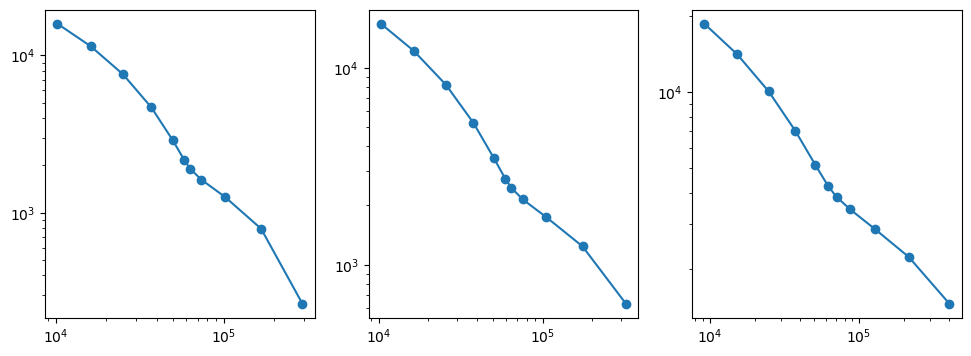

In [24]:
# L-curve
fig = plt.figure(figsize = (16, 4))

ax = fig.add_subplot(141)
ax.loglog(rss_temp_del12, pen_temp_del12, "o-")

ax = fig.add_subplot(142)
ax.loglog(rss_temp_del23, pen_temp_del23, "o-")

ax = fig.add_subplot(143)
ax.loglog(rss_temp_del34, pen_temp_del34, "o-")

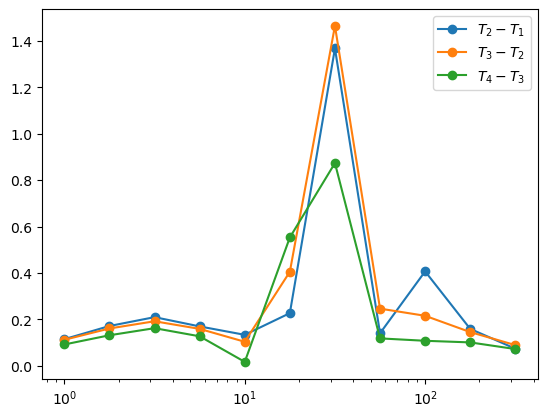

In [25]:
plt.semilogx(lams, calcCurvature2(np.log(rss_temp_del12), np.log(pen_temp_del12)), "o-", label = "$T_2 - T_1$")
plt.semilogx(lams, calcCurvature2(np.log(rss_temp_del23), np.log(pen_temp_del23)), "o-", label = "$T_3 - T_2$")
plt.semilogx(lams, calcCurvature2(np.log(rss_temp_del34), np.log(pen_temp_del34)), "o-", label = "$T_4 - T_3$")
plt.legend()

In [26]:
num_opt_12 = np.argmax(calcCurvature2(np.log(rss_temp_del12), np.log(pen_temp_del12)))
num_opt_23 = np.argmax(calcCurvature2(np.log(rss_temp_del23), np.log(pen_temp_del23)))
num_opt_34 = np.argmax(calcCurvature2(np.log(rss_temp_del34), np.log(pen_temp_del34)))

print(num_opt_12, num_opt_23, num_opt_34)

6 6 6


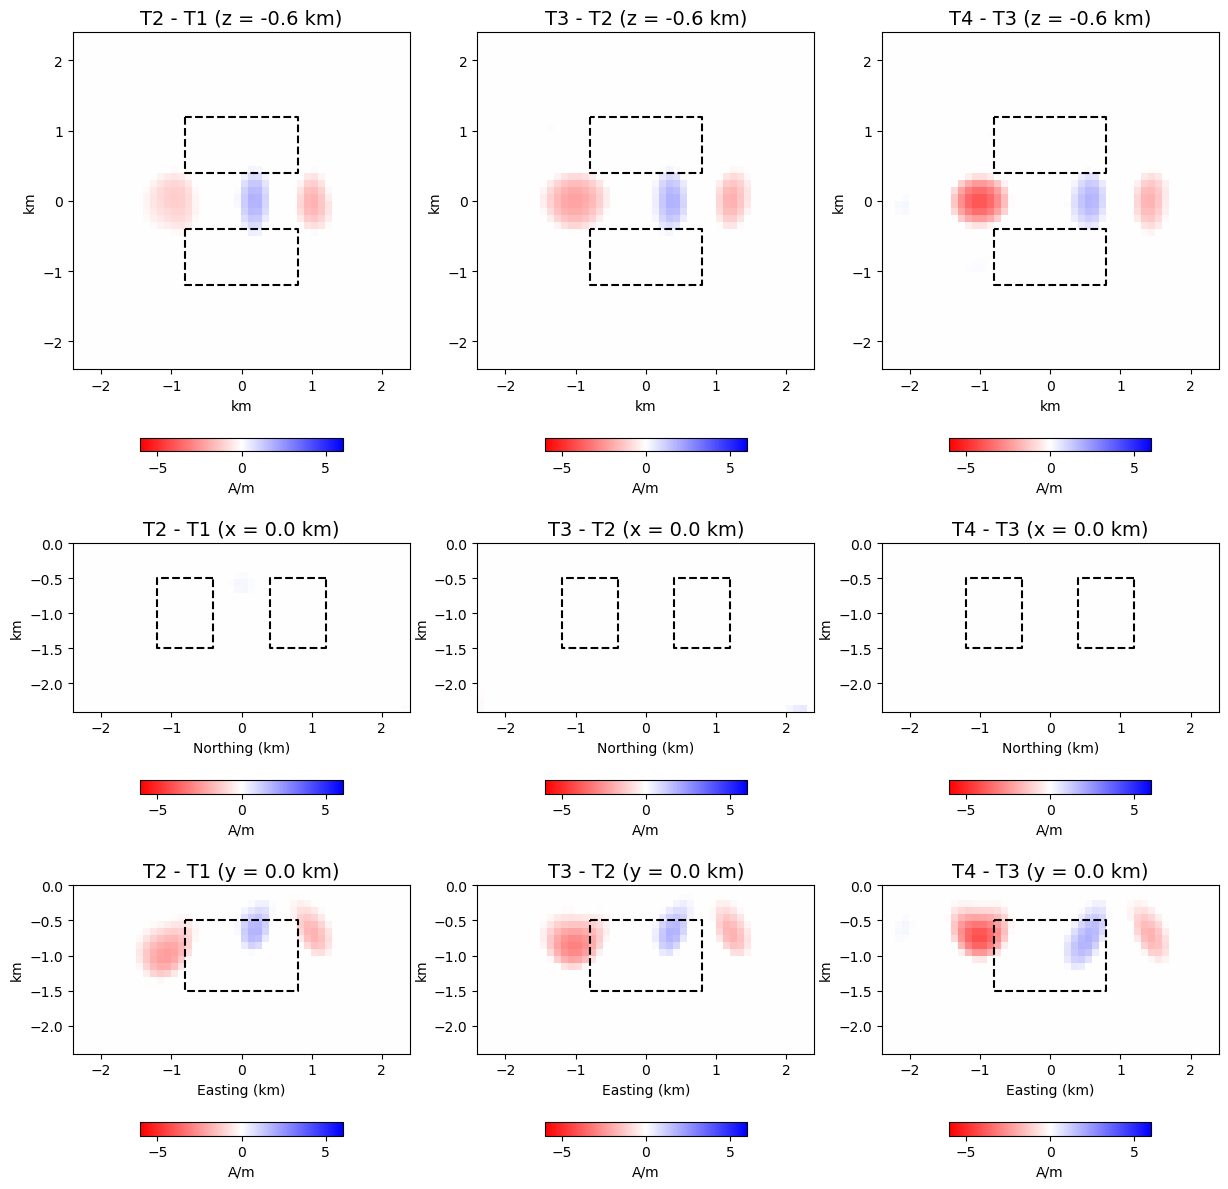

In [28]:
fig = plt.figure(figsize = (20, 20))

x_slice =  0.0
y_slice =  0.0
z_slice = -0.6

ax = fig.add_subplot(341)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              betas_del12_all[num_opt_12].reshape(xx2.shape)[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([-0.8, -0.8, 0.8, 0.8, -0.8], [1.2, 0.4, 0.4, 1.2, 1.2], "--", color = "k")
ax.plot([-0.8, -0.8, 0.8, 0.8, -0.8], [-0.4, -1.2, -1.2, -0.4, -0.4], "--", color = "k")

ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 - T1 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(342)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              betas_del23_all[num_opt_23].reshape(xx2.shape)[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([-0.8, -0.8, 0.8, 0.8, -0.8], [1.2, 0.4, 0.4, 1.2, 1.2], "--", color = "k")
ax.plot([-0.8, -0.8, 0.8, 0.8, -0.8], [-0.4, -1.2, -1.2, -0.4, -0.4], "--", color = "k")

ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 - T2 (z = {:.1f} km)".format(z_slice), fontsize = 14)

ax = fig.add_subplot(343)
p = ax.pcolor(xx2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              yy2[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx), 
              betas_del34_all[num_opt_34].reshape(xx2.shape)[np.abs(zz2 - z_slice) < 0.5*incz].reshape(ny, nx),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([-0.8, -0.8, 0.8, 0.8, -0.8], [1.2, 0.4, 0.4, 1.2, 1.2], "--", color = "k")
ax.plot([-0.8, -0.8, 0.8, 0.8, -0.8], [-0.4, -1.2, -1.2, -0.4, -0.4], "--", color = "k")

ax.set_xlabel("km")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 - T3 (z = {:.1f} km)".format(z_slice), fontsize = 14)


ax = fig.add_subplot(345)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              betas_del12_all[num_opt_12].reshape(xx2.shape)[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([1.2, 0.4, 0.4, 1.2, 1.2], [-0.5, -0.5, -1.5, -1.5, -0.5], "--", color = "k")
ax.plot([-0.4, -1.2, -1.2, -0.4, -0.4], [-0.5, -0.5, -1.5, -1.5, -0.5], "--", color = "k")

ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 - T1 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(346)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              betas_del23_all[num_opt_23].reshape(xx2.shape)[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([1.2, 0.4, 0.4, 1.2, 1.2], [-0.5, -0.5, -1.5, -1.5, -0.5], "--", color = "k")
ax.plot([-0.4, -1.2, -1.2, -0.4, -0.4], [-0.5, -0.5, -1.5, -1.5, -0.5], "--", color = "k")

ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 - T2 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(347)
p = ax.pcolor(yy2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              zz2[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny), 
              betas_del34_all[num_opt_34].reshape(xx2.shape)[np.abs(xx2 - x_slice) < 0.5*incz].reshape(nz, ny),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([1.2, 0.4, 0.4, 1.2, 1.2], [-0.5, -0.5, -1.5, -1.5, -0.5], "--", color = "k")
ax.plot([-0.4, -1.2, -1.2, -0.4, -0.4], [-0.5, -0.5, -1.5, -1.5, -0.5], "--", color = "k")

ax.set_xlabel("Northing (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 - T3 (x = {:.1f} km)".format(x_slice), fontsize = 14)

ax = fig.add_subplot(349)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              betas_del12_all[num_opt_12].reshape(xx2.shape)[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([-0.8, 0.8, 0.8, -0.8, -0.8], [-0.5, -0.5, -1.5, -1.5, -0.5], "--", color = "k")

ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T2 - T1 (y = {:.1f} km)".format(y_slice), fontsize = 14)

ax = fig.add_subplot(3,4,10)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              betas_del23_all[num_opt_23].reshape(xx2.shape)[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([-0.8, 0.8, 0.8, -0.8, -0.8], [-0.5, -0.5, -1.5, -1.5, -0.5], "--", color = "k")

ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T3 - T2 (y = {:.1f} km)".format(y_slice), fontsize = 14)

ax = fig.add_subplot(3,4,11)
p = ax.pcolor(xx2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              zz2[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx), 
              betas_del34_all[num_opt_34].reshape(xx2.shape)[np.abs(yy2 - y_slice) < 0.5*incy].reshape(nz, nx),
              cmap = "bwr_r"
             )
p.set_clim(-6, 6)
plt.colorbar(p, orientation = "horizontal", shrink = 0.6, aspect = 15, label = "A/m", pad = 0.08)

ax.plot([-0.8, 0.8, 0.8, -0.8, -0.8], [-0.5, -0.5, -1.5, -1.5, -0.5], "--", color = "k")

ax.set_xlabel("Easting (km)")
ax.set_ylabel("km")
ax.set_aspect("equal")
ax.set_title("T4 - T3 (y = {:.1f} km)".format(y_slice), fontsize = 14)

plt.subplots_adjust(hspace=-0.6)